In [1]:
pip install neo4j

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "UTSGSDDestiaRika052")  
DB = "neo4j"

In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_=DB,
    )

In [4]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_=DB, routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

In [5]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


1. Apa nama database yang digunakan pada tutorial ini?
Jawab : Namanya neo4j. Nama itu ditulis di kode sebagai DB = "neo4j". Ini database bawaan yang otomatis ada saat Neo4j pertama kali dipasang.

2. Sebutkan akses lain untuk mengakses database lain dalam 1 instance!
Jawab : Satu Neo4j bisa punya banyak database. Cara membuka database yang lain:
- Di Cypher: tulis USE namadatabase di depan query. Contoh: USE toko MATCH (n) RETURN n
- Di Python: ganti isi DB. Contoh: DB = "toko"
- Untuk membuat atau melihat database: pakai CREATE DATABASE toko, SHOW DATABASES, atau DROP DATABASE toko.

3. Apa jenis graf pertemanan yang telah dibuat di sini?
Jawab : Jenisnya graf berarah. Hubungannya punya arah panah: Arthur → Guinevere, artinya Arthur kenal Guinevere. Belum tentu sebaliknya. Grafnya juga tidak berbobot, karena hubungan pertemanannya tidak punya angka atau nilai. Bentuknya seperti bintang, dengan Arthur di tengah dan tiga temannya di sekelilingnya.

In [6]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(r"C:\Users\Destia Rika\semester 7\graf\uts graf\ecommerce-dataset")

for f in sorted(DATA_DIR.glob("*.csv")):
    print(f"\n=== {f.name} ===")
    display(pd.read_csv(f, nrows=5))


=== category_tree.csv ===


,categoryid,parentid
0,1016,213
1,809,169
2,570,9
3,1691,885
4,536,1691



=== events.csv ===


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



=== events_P1_train_0506-0725.csv ===


...

,timestamp,visitorid,event,itemid,transactionid
0,1435717475012,457980,view,278224,NaN
1,1435718665275,554795,view,6605,NaN
2,1435720737471,1291838,view,444688,NaN
3,1435717706116,567028,view,296749,NaN
4,1435721029856,174978,view,99274,NaN



=== item_properties_part1.csv ===


,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513



=== item_properties_part2.csv ===


,timestamp,itemid,property,value
0,1433041200000,183478,561,769062
1,1439694000000,132256,976,n26.400 1135780
2,1435460400000,420307,921,1149317 1257525
3,1431831600000,403324,917,1204143
4,1435460400000,230701,521,769062


---
# Lanjutan: Neo4j + dataset RetailRocket

In [7]:
import argparse
import os
import time

import numpy as np
import networkx as nx
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from tqdm import tqdm

## 2. Membuat session / koneksi Neo4j (dengan argparse)
`driver.session(database="system")` dipakai untuk melihat daftar database. Argumen koneksi dibaca lewat `argparse`. Di notebook, daftar argumen diberikan manual ke `parse_args`.

In [8]:
def parse_arguments(argv=None):
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument("-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)")
    parser.add_argument("-p", "--password", default="neo4j", help="Password Neo4J (default: neo4j)")
    parser.add_argument("-b", "--bolt", default="bolt://127.0.0.1:7687",
                        help="Neo4J URI / Bolt (default: bolt://127.0.0.1:7687)")
    parser.add_argument("-s", "--source", default="data", help="Direktori/folder sumber data (default: data)")
    return parser.parse_args(argv)


args = parse_arguments(["-u", AUTH[0], "-p", AUTH[1], "-b", URI, "-s", str(DATA_DIR)])

# Cek berkas events.csv
csv_file_path = os.path.join(args.source, "events.csv")
if not os.path.exists(csv_file_path):
    raise FileNotFoundError(f"Error: File '{csv_file_path}' tidak ditemukan!")

# Koneksi ke Neo4j
try:
    driver = GraphDatabase.driver(args.bolt, auth=(args.user, args.password))
    driver.verify_connectivity()
except Exception as e:
    raise ConnectionError(f"Gagal terhubung ke database: {e}")

# Session baru ke database "system"
with driver.session(database="system") as session:
    daftar_db = session.run("SHOW DATABASES YIELD name, currentStatus").data()
print(pd.DataFrame(daftar_db))

     name currentStatus
0   neo4j        online
1  system        online


## 2.1 Wrangling dan EDA

Ringkasan isi file:
- `events.csv`: log interaksi (`timestamp`, `visitorid`, `event` = view/addtocart/transaction, `itemid`, `transactionid`). Ini bahan utama graf.
- `category_tree.csv`: hubungan kategori dan induknya.
- `item_properties_part1/2.csv`: properti tiap item (berukuran besar, tidak dibutuhkan untuk graf interaksi).

Graf yang dibangun hanya dari `events.csv`: **Visitor –[VIEWED / ADDED_TO_CART / BOUGHT]→ Item**.

### 2.1 no. 1 dan 2: Menentukan dua periode waktu dan memfilter data
Data `events.csv` mencakup 3 Mei 2015 sampai 18 September 2015. Periode yang saya pakai (tidak saling tumpang tindih; tanggal akhir ikut dihitung, waktu dalam UTC):

| Fold | Periode | Fungsi |
|---|---|---|
| **P1 (training)** | 06 Mei 2015 – 25 Juli 2015 | dibangun menjadi graf di Neo4j, dasar rekomendasi |
| **P2 (testing)** | 26 Juli 2015 – 15 Agustus 2015 | kunci jawaban untuk menghitung Hit@5 dan NDCG@5 |

Filter dilakukan pada kolom `timestamp` (milidetik sejak 1970, UTC), lalu hasilnya disimpan ke file CSV.

In [9]:
# RAM terbatas, jadi file dibaca per potongan (chunk) dan langsung difilter per periode
tipe = {"timestamp": "int64", "visitorid": "int64", "itemid": "int64",
        "event": "category", "transactionid": "Int64"}


def ms(tanggal):  # tanggal -> milidetik sejak 1970 (UTC), sama dengan kolom timestamp
    return int(pd.Timestamp(tanggal).timestamp() * 1000)


# Tanggal akhir ikut dihitung (inklusif), jadi batas atasnya = hari berikutnya pukul 00:00 (UTC)
P1_START, P1_END = ms("2015-05-06"), ms("2015-07-26")  # [6 Mei, 25 Juli]
P2_START, P2_END = ms("2015-07-26"), ms("2015-08-16")  # [26 Juli, 15 Agustus]

bag_p1, bag_p2 = [], []
ts_min, ts_max, total_baris = None, None, 0
for chunk in pd.read_csv(DATA_DIR / "events.csv", dtype=tipe, chunksize=250_000):
    total_baris += len(chunk)
    ts_min = chunk["timestamp"].min() if ts_min is None else min(ts_min, chunk["timestamp"].min())
    ts_max = chunk["timestamp"].max() if ts_max is None else max(ts_max, chunk["timestamp"].max())
    bag_p1.append(chunk[(chunk["timestamp"] >= P1_START) & (chunk["timestamp"] < P1_END)])
    bag_p2.append(chunk[(chunk["timestamp"] >= P2_START) & (chunk["timestamp"] < P2_END)])

print(f"Total baris events.csv: {total_baris:,}")
print("Rentang data:", pd.to_datetime(ts_min, unit="ms"), "s.d.", pd.to_datetime(ts_max, unit="ms"))

p1 = pd.concat(bag_p1, ignore_index=True)
p2 = pd.concat(bag_p2, ignore_index=True)
del bag_p1, bag_p2

# Pastikan kedua periode tidak tumpang tindih
assert p1["timestamp"].max() < p2["timestamp"].min()

P1_CSV = DATA_DIR / "events_P1_train_0506-0725.csv"
P2_CSV = DATA_DIR / "events_P2_test_0726-0815.csv"
p1.to_csv(P1_CSV, index=False)
p2.to_csv(P2_CSV, index=False)

ringkas = pd.DataFrame({
    "baris": [len(p1), len(p2)],
    "visitor unik": [p1["visitorid"].nunique(), p2["visitorid"].nunique()],
    "item unik": [p1["itemid"].nunique(), p2["itemid"].nunique()],
}, index=["P1 train (6 Mei - 25 Jul 2015)", "P2 test (26 Jul - 15 Agu 2015)"])
display(ringkas)
display(pd.concat([p1["event"].value_counts().rename("P1"), p2["event"].value_counts().rename("P2")], axis=1))

Total baris events.csv: 2,756,101
Rentang data: 2015-05-03 03:00:04.384000 s.d. 2015-09-18 02:59:47.788000


,baris,visitor unik,item unik
P1 train (6 Mei - 25 Jul 2015),1696556,864215,191337
P2 test (26 Jul - 15 Agu 2015),411870,230168,95963


,P1,P2
event,,
view,1641096,397812
addtocart,41770,10663
transaction,13690,3395


## Impor P1 ke Neo4j (batch)
Struktur graf: `(:Visitor {visitorId})-[:VIEWED|ADDED_TO_CART|BOUGHT {timestamp}]->(:Item {itemId})`.
Impor dilakukan per batch (`chunksize`) supaya memori aman. Sebelum impor, graf lama (Visitor/Item) dibersihkan agar relasi tidak dobel jika sel dijalankan ulang. Node `Person` dari tutorial tidak disentuh.

In [10]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")


def reset_graph(session):
    """Hapus semua node Visitor/Item (beserta relasinya) secara bertahap."""
    while True:
        n = session.run(
            "MATCH (n) WHERE n:Visitor OR n:Item "
            "WITH n LIMIT 50000 DETACH DELETE n RETURN count(*) AS c"
        ).single()["c"]
        if n == 0:
            break


def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [11]:
batch_size = 2000        # batch kecil supaya hemat memori (RAM laptop terbatas)
FORCE_REIMPORT = False   # True = hapus graf lama lalu impor ulang dari nol
csv_file_path = str(P1_CSV)

with driver.session(database=DB) as session:
    sudah_ada = session.run("MATCH (:Visitor)-[r]->(:Item) RETURN count(r) AS c").single()["c"]

if sudah_ada == len(p1) and not FORCE_REIMPORT:
    print(f"Graf P1 sudah lengkap di Neo4j ({sudah_ada:,} relasi). Impor dilewati.")
else:
    t0 = time.time()
    with driver.session(database=DB) as session:
        reset_graph(session)
        create_constraints(session)

        print(f"Membaca file data dari: {csv_file_path}")
        chunks = pd.read_csv(csv_file_path, chunksize=batch_size, dtype={"transactionid": "Int64"})

        total_rows = len(p1)
        total_chunks = (total_rows // batch_size) + 1

        print("Memulai proses impor data ke Neo4j...")
        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data", mininterval=10):
            # Membersihkan data null/NaN pada transactionid
            chunk["transactionid"] = chunk["transactionid"].astype("string").fillna("")
            chunk["event"] = chunk["event"].astype(str)
            records = chunk.to_dict(orient="records")
            session.execute_write(import_batch, records)

    print(f"Proses impor berhasil. Waktu: {time.time() - t0:.0f} detik")

Graf P1 sudah lengkap di Neo4j (1,696,556 relasi). Impor dilewati.


### 2.1 no. 3: Komposisi subgraph yang dibuat
Query Cypher dijalankan lewat Python API (`driver.execute_query`):
- `MATCH (n) WHERE n:Visitor OR n:Item RETURN labels(n)[0], count(n)` : menghitung node per jenis (label).
- `MATCH (:Visitor)-[r]->(:Item) RETURN type(r), count(r)` : menghitung relasi per jenis.
- `labels(n)` mengembalikan daftar label sebuah node, `type(r)` mengembalikan nama relasi, `count()` menjumlahkan.

In [12]:
def query_df(query, **params):
    return driver.execute_query(
        query, params, database_=DB, routing_=RoutingControl.READ,
        result_transformer_=lambda r: r.to_df(),
    )


q_nodes = """
MATCH (n) WHERE n:Visitor OR n:Item
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
"""
q_rels = """
MATCH (:Visitor)-[r]->(:Item)
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""
df_nodes = query_df(q_nodes)
df_rels = query_df(q_rels)
display(df_nodes)
display(df_rels)
print("Total simpul :", df_nodes["jumlah"].sum())
print("Total relasi :", df_rels["jumlah"].sum(), "(harus sama dengan jumlah baris P1 =", len(p1), ")")

,jenis_simpul,jumlah
0,Visitor,864215
1,Item,191337


,jenis_relasi,jumlah
0,VIEWED,1641096
1,ADDED_TO_CART,41770
2,BOUGHT,13690


Total simpul : 1055552
Total relasi : 1696556 (harus sama dengan jumlah baris P1 = 1696556 )


**Penjelasan:** subgraph punya 2 jenis simpul, yaitu `Visitor` (pengunjung) dan `Item` (barang), dan 3 jenis relasi berarah dari Visitor ke Item: `VIEWED` (melihat), `ADDED_TO_CART` (masuk keranjang), `BOUGHT` (membeli). Jumlah relasi sama dengan jumlah baris data P1, jadi tidak ada data yang hilang saat impor. Satu visitor bisa punya banyak relasi ke item yang sama (misalnya melihat 3 kali), karena setiap kejadian disimpan sebagai relasi terpisah beserta `timestamp`-nya.

### 2.1 no. 4: Vector Space Modeling (VSM), simpul sebagai **User**
Setiap User dijadikan satu vektor, dimensinya adalah seluruh Item. Nilai sel = bobot interaksi User terhadap Item. Bobot saya tentukan berdasarkan kekuatan sinyal: **VIEWED = 1, ADDED_TO_CART = 3, BOUGHT = 5**, dan bobot dijumlahkan jika interaksinya berulang.

Cypher yang dipakai menjumlahkan bobot per pasangan (Visitor, Item) langsung di Neo4j:
`MATCH (v:Visitor)-[r]->(i:Item) RETURN v.visitorId, i.itemId, sum(CASE type(r) WHEN 'VIEWED' THEN 1 ... END)`

In [13]:
W_VIEW, W_CART, W_BUY = 1, 3, 5

q_vsm = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitor, i.itemId AS item,
       sum(CASE type(r)
             WHEN 'VIEWED' THEN $w_view
             WHEN 'ADDED_TO_CART' THEN $w_cart
             WHEN 'BOUGHT' THEN $w_buy
             ELSE 0 END) AS bobot
"""
edges = query_df(q_vsm, w_view=W_VIEW, w_cart=W_CART, w_buy=W_BUY)
print("Pasangan (visitor, item) unik:", len(edges))

user_ids = np.sort(edges["visitor"].unique())
item_ids = np.sort(edges["item"].unique())
u_idx = np.searchsorted(user_ids, edges["visitor"].to_numpy())
i_idx = np.searchsorted(item_ids, edges["item"].to_numpy())

# VSM User: baris = user, kolom = item
X_user = sp.csr_matrix(
    (edges["bobot"].to_numpy(dtype=np.float32), (u_idx, i_idx)),
    shape=(len(user_ids), len(item_ids)),
)


def sifat_matriks(M, nama):
    nnz_per_baris = np.diff(M.indptr)
    mem = (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6
    return pd.Series({
        "shape": f"{M.shape[0]:,} x {M.shape[1]:,}",
        "jumlah baris": M.shape[0],
        "dimensi (jumlah kolom)": M.shape[1],
        "sel terisi (non-zero)": M.nnz,
        "kepadatan (density)": f"{M.nnz / (M.shape[0] * M.shape[1]):.6%}",
        "rata-rata non-zero per baris": round(nnz_per_baris.mean(), 2),
        "median non-zero per baris": float(np.median(nnz_per_baris)),
        "baris dengan hanya 1 non-zero": f"{(nnz_per_baris == 1).mean():.1%}",
        "memori sparse (MB)": round(mem, 1),
    }, name=nama)


prop_user = sifat_matriks(X_user, "VSM User")
display(prop_user.to_frame())

Pasangan (visitor, item) unik: 1315648


,VSM User
shape,"864,215 x 191,337"
jumlah baris,864215
dimensi (jumlah kolom),191337
sel terisi (non-zero),1315648
kepadatan (density),0.000796%
rata-rata non-zero per baris,1.52
median non-zero per baris,1.0
baris dengan hanya 1 non-zero,79.9%
memori sparse (MB),14.0


Fungsi untuk menggambar sebagian VSM sebagai graf dengan **networkx** (graf penuh terlalu besar untuk digambar, jadi diambil contoh baris dengan interaksi terbanyak):

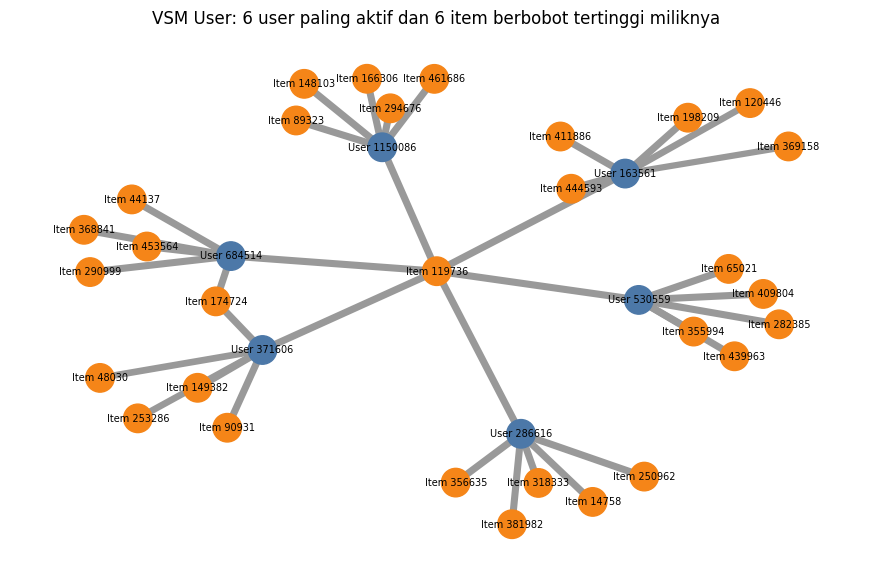

In [14]:
def plot_vsm_networkx(M, row_ids, col_ids, row_name, col_name, title, n_rows=6, n_cols=6):
    """Gambar graf bipartit dari sebagian VSM: baris (biru) dan kolom (oranye), tebal garis = bobot."""
    nnz = np.diff(M.indptr)
    top_rows = np.argsort(-nnz)[:n_rows]
    G = nx.Graph()
    for r in top_rows:
        row = M.getrow(r)
        pilih = np.argsort(-row.data)[:n_cols]
        rn = f"{row_name} {row_ids[r]}"
        G.add_node(rn, jenis="baris")
        for c, w in zip(row.indices[pilih], row.data[pilih]):
            cn = f"{col_name} {col_ids[c]}"
            G.add_node(cn, jenis="kolom")
            G.add_edge(rn, cn, weight=float(w))
    pos = nx.spring_layout(G, seed=42, k=0.6)
    warna = ["#4C78A8" if G.nodes[n]["jenis"] == "baris" else "#F58518" for n in G]
    lebar = [0.6 + 0.3 * min(G[u][v]["weight"], 15) for u, v in G.edges]  # tebal dibatasi agar tetap terbaca
    plt.figure(figsize=(11, 7))
    nx.draw_networkx(G, pos, node_color=warna, width=lebar, edge_color="#999999",
                     font_size=7, node_size=420, with_labels=True)
    plt.title(title)
    plt.axis("off")
    plt.show()


plot_vsm_networkx(X_user, user_ids, item_ids, "User", "Item",
                  "VSM User: 6 user paling aktif dan 6 item berbobot tertinggi miliknya")

**Karakteristik VSM User** (lihat tabel di atas):
- **Dimensi** = jumlah Item unik di P1 (satu kolom per item), yaitu 191.337.
- **Shape** = (jumlah User x jumlah Item).
- Matriks sangat **jarang (sparse)**: hampir semua sel bernilai 0 karena satu user hanya berinteraksi dengan sedikit item. Karena itu disimpan dalam format sparse CSR, bukan matriks penuh.

### 2.1 no. 5: VSM dengan simpul sebagai **Item**
Sekarang kebalikannya: setiap Item menjadi satu vektor dengan dimensi seluruh User. Datanya sama, hanya sumbunya ditukar (transpose).

,VSM Item
shape,"191,337 x 864,215"
jumlah baris,191337
dimensi (jumlah kolom),864215
sel terisi (non-zero),1315648
kepadatan (density),0.000796%
rata-rata non-zero per baris,6.88
median non-zero per baris,2.0
baris dengan hanya 1 non-zero,38.6%
memori sparse (MB),11.3


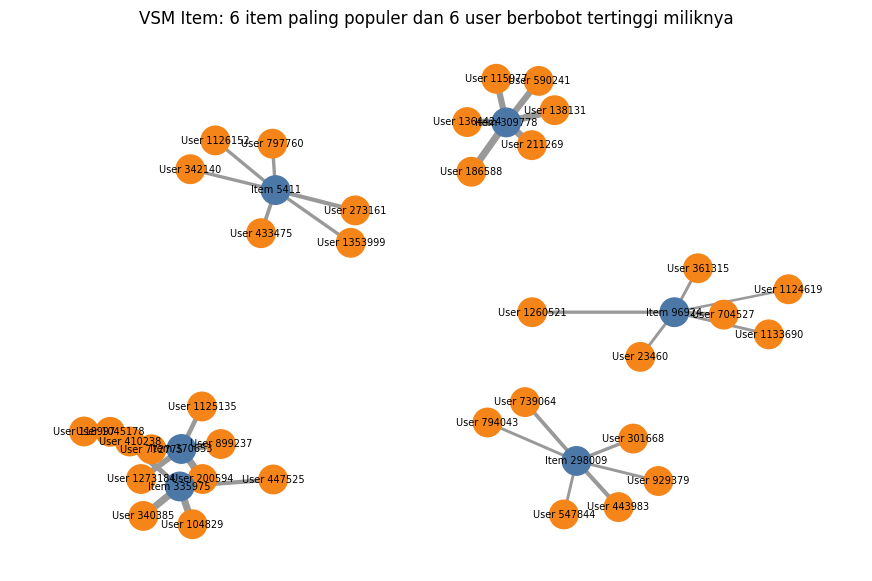

In [15]:
X_item = X_user.T.tocsr()  # baris = item, kolom = user

prop_item = sifat_matriks(X_item, "VSM Item")
display(prop_item.to_frame())

plot_vsm_networkx(X_item, item_ids, user_ids, "Item", "User",
                  "VSM Item: 6 item paling populer dan 6 user berbobot tertinggi miliknya")

**Karakteristik VSM Item:** shape (Item x User), dimensinya = jumlah User unik. Sama-sama sparse, tetapi bentuknya berbeda: baris lebih sedikit dan tiap baris (item) rata-rata diisi oleh lebih banyak user.

### 2.1 no. 6: Proyeksi mana yang lebih baik (efektif/efisien)?
Dua proyeksi dibandingkan dari ukuran, kepadatan, dan waktu menghitung cosine similarity satu baris acuan terhadap semua baris lain (rata-rata 20 baris acuan acak).

In [16]:
def waktu_similarity(M, n_uji=20, seed=42):
    Mn = normalize(M, norm="l2", axis=1)
    rng = np.random.default_rng(seed)
    ref = rng.choice(M.shape[0], size=n_uji, replace=False)
    t0 = time.perf_counter()
    for r in ref:
        _ = (Mn @ Mn[r].T).toarray().ravel()
    return (time.perf_counter() - t0) / n_uji


bandingkan = pd.DataFrame({"VSM User": prop_user, "VSM Item": prop_item})
bandingkan.loc["waktu similarity 1 baris vs semua (detik)"] = [
    round(waktu_similarity(X_user), 4), round(waktu_similarity(X_item), 4)]
n_u, n_i = X_user.shape
bandingkan.loc["ukuran matriks similarity penuh (sel)"] = [f"{n_u**2:,}", f"{n_i**2:,}"]
bandingkan.loc["perkiraan memori matriks penuh float32 (GB)"] = [round(n_u**2 * 4 / 1e9, 1), round(n_i**2 * 4 / 1e9, 1)]
display(bandingkan)

,VSM User,VSM Item
shape,"864,215 x 191,337","191,337 x 864,215"
jumlah baris,864215,191337
dimensi (jumlah kolom),191337,864215
sel terisi (non-zero),1315648,1315648
kepadatan (density),0.000796%,0.000796%
rata-rata non-zero per baris,1.52,6.88
median non-zero per baris,1.0,2.0
baris dengan hanya 1 non-zero,79.9%,38.6%
memori sparse (MB),14.0,11.3
waktu similarity 1 baris vs semua (detik),0.0408,0.0634


**Kesimpulan no. 6: proyeksi mana yang lebih baik?** Berdasarkan tabel di atas, proyeksi **Item (VSM Item) lebih baik**, baik dari sisi efisiensi maupun efektivitas.

| Aspek | VSM User | VSM Item | Artinya |
|---|---|---|---|
| Jumlah baris (objek yang dibandingkan) | 864.215 | 191.337 | Item hanya sekitar 22% dari jumlah user, jadi jauh lebih sedikit yang harus dibandingkan |
| Ukuran matriks similarity penuh | 746,9 miliar sel (sekitar 2.988 GB) | 36,6 miliar sel (sekitar 146 GB) | Proyeksi Item sekitar 20 kali lebih kecil |
| Rata-rata non-zero per baris | 1,52 | 6,88 | Vektor item lebih "kaya" informasi |
| Baris yang hanya punya 1 non-zero | 79,9% | 38,6% | Banyak user hanya menyentuh 1 item, sehingga hampir tidak bisa dibandingkan dengan user lain |
| Waktu 1 baris vs semua | sekitar 0,04 detik | sekitar 0,05 detik | Sama-sama cepat (puluhan milidetik) karena jumlah sel terisinya sama |

**Alasan:**
- **Efisien:** jumlah sel terisi (1.315.648) sama pada kedua proyeksi, jadi memori matriks dan waktu satu perhitungan sama-sama kecil. Bedanya ada pada matriks similarity penuh: user jauh lebih banyak daripada item, sehingga proyeksi User menghasilkan matriks similarity yang jauh lebih besar.
- **Efektif:** sebagian besar user (79,9%) hanya berinteraksi dengan satu item, sehingga cosine similarity antar user kurang bermakna (hanya bisa mirip jika kebetulan melihat item yang sama). Item lebih banyak dilihat oleh beberapa user sekaligus, jadi pola "item yang sering dilihat bersamaan" lebih mudah ditemukan.
- Selain itu, kemiripan antar item cenderung lebih stabil terhadap waktu daripada kemiripan antar user.

Karena itu, perhitungan similarity (no. 7), query Cypher (no. 8), dan KNN rekomendasi (2.2) selanjutnya memakai **proyeksi Item** (item-based).

### 2.1 no. 7: Perhitungan similarity pada graf yang terproyeksi (Python)
Similarity yang dipakai adalah **cosine similarity** antar vektor item pada VSM Item. Setiap vektor dinormalisasi (panjang = 1), sehingga cosine similarity cukup berupa perkalian titik. Nilainya 0 sampai 1 (semua bobot tidak negatif): makin dekat ke 1, makin mirip pola user yang berinteraksi dengan kedua item itu.

In [17]:
Xn_item = normalize(X_item, norm="l2", axis=1).tocsr()  # item x user, tiap baris panjang 1
item_pos = {int(v): k for k, v in enumerate(item_ids)}  # itemId -> nomor baris
user_pos = {int(v): k for k, v in enumerate(user_ids)}  # visitorId -> nomor baris


def similarity_item(j):
    """Cosine similarity item j (nomor baris) terhadap semua item."""
    s = (Xn_item @ Xn_item[j].T).toarray().ravel()
    s[j] = 0.0  # similarity dengan dirinya sendiri tidak dihitung
    return s


def top_k_item(j, k=5):
    """k item paling mirip dengan item j (hanya yang similarity > 0). Urutan stabil: skor turun, lalu indeks."""
    s = similarity_item(j)
    nz = np.flatnonzero(s > 0)
    urut = np.lexsort((nz, -s[nz]))[:k]
    return nz[urut], s[nz[urut]]


# Contoh: 5 item paling mirip dengan item yang paling banyak dilihat user
j_contoh = int(np.argmax(np.diff(X_item.indptr)))
nb, sim = top_k_item(j_contoh, 5)
print("Item acuan:", item_ids[j_contoh], f"(dilihat {np.diff(X_item.indptr)[j_contoh]} user)")
display(pd.DataFrame({"itemId": item_ids[nb], "cosine similarity": sim.round(4)}))

Item acuan: 5411 (dilihat 1672 user)


,itemId,cosine similarity
0,33030,0.1442
1,37807,0.0998
2,33956,0.0961
3,256242,0.0916
4,89143,0.0802


## 2.2 Analytics
### 2.2 no. 1a: Memilih seorang user secara acak dan merekomendasikan dengan KNN
**Cara kerja KNN item-based** (k = 5):
1. Ambil semua item yang pernah disentuh user di periode training (P1), lengkap dengan bobotnya (view=1, addtocart=3, bought=5).
2. Untuk tiap item milik user, cari **5 item tetangga terdekat** (k = 5) berdasarkan cosine similarity.
3. Skor kandidat = jumlah dari (bobot item user x similarity). Item yang sudah pernah disentuh user dibuang.
4. Urutkan skor dari tertinggi: 5 teratas menjadi daftar rekomendasi (dipakai untuk Hit@5 dan NDCG@5), dan **3 teratas** menjadi item yang diiklankan.

**Kunci jawaban:** item yang disentuh user di P2 (testing) tetapi **belum pernah** disentuhnya di P1. Item yang sudah pernah dilihat di P1 tidak dihitung, karena sistem rekomendasi memang tidak merekomendasikan item yang sudah diketahui user.

**Pemilihan user acak (bisa direproduksi, seed = 42):** kandidatnya adalah user yang punya minimal 3 item di P1 dan minimal 1 item baru di P2 (agar ada kunci jawaban untuk dievaluasi). Kandidat diacak dengan seed tetap, lalu diambil yang pertama yang bisa menghasilkan 5 rekomendasi.

In [18]:
K = 5          # jumlah tetangga terdekat (KNN)
N_REC = 5      # panjang daftar rekomendasi untuk Hit@5 / NDCG@5
SEED = 42


def knn_item_user(u):
    """Tetangga terdekat (k=K) untuk setiap item milik user u (nomor baris)."""
    baris = X_user[u]
    return {int(j): (*top_k_item(j, K), float(w)) for j, w in zip(baris.indices, baris.data)}


def rekomendasi_knn(u, n_rec=N_REC):
    """Daftar [(nomor_baris_item, skor)] terurut turun, tanpa item yang sudah disentuh user."""
    knn = knn_item_user(u)
    skor = {}
    for j, (nb, sim, w) in knn.items():
        for n, s in zip(nb, sim):
            skor[int(n)] = skor.get(int(n), 0.0) + w * float(s)
    kandidat = [(n, s) for n, s in skor.items() if n not in knn]
    kandidat.sort(key=lambda x: (-x[1], x[0]))
    return kandidat[:n_rec], knn


# Item yang disentuh user di P2 (hanya item yang ada di katalog P1, karena item baru tidak mungkin direkomendasikan)
ada_p1 = np.diff(X_user.indptr) >= 3
pool_ids = user_ids[ada_p1]
p2_valid = p2[p2["visitorid"].isin(pool_ids) & p2["itemid"].isin(item_ids)]
uji = p2_valid.groupby("visitorid")["itemid"].agg(lambda s: set(map(int, s))).to_dict()

# Kunci jawaban = item P2 yang BELUM pernah disentuh user di P1
kunci = {}
for uid, items_p2 in uji.items():
    sudah_ada = set(map(int, item_ids[X_user[user_pos[uid]].indices]))
    baru = items_p2 - sudah_ada
    if baru:
        kunci[uid] = baru
print(f"User dengan >=3 item di P1 dan >=1 item di P2 : {len(uji):,}")
print(f"... dan punya minimal 1 item BARU di P2       : {len(kunci):,}")

rng = np.random.default_rng(SEED)
kandidat_user = rng.permutation(np.array(sorted(kunci)))

user_terpilih = None
for uid in kandidat_user:
    rec, knn = rekomendasi_knn(user_pos[int(uid)])
    if len(rec) == N_REC:
        user_terpilih = int(uid)
        break
print("User terpilih (visitorId):", user_terpilih)

User dengan >=3 item di P1 dan >=1 item di P2 : 4,518
... dan punya minimal 1 item BARU di P2       : 3,780


User terpilih (visitorId): 621392


In [19]:
u = user_pos[user_terpilih]
rec, knn = rekomendasi_knn(u)

# Riwayat user di P1 (dari graf)
riwayat = query_df("""
MATCH (v:Visitor {visitorId: $uid})-[r]->(i:Item)
RETURN i.itemId AS itemId, type(r) AS interaksi, count(r) AS jumlah
ORDER BY itemId, interaksi
""", uid=user_terpilih)
print(f"Riwayat user {user_terpilih} di periode P1:")
display(riwayat)

tabel_rec = pd.DataFrame({
    "peringkat": range(1, len(rec) + 1),
    "itemId": [int(item_ids[n]) for n, _ in rec],
    "skor": [round(s, 4) for _, s in rec],
})
tabel_rec["diiklankan (top-3)"] = tabel_rec["peringkat"] <= 3
print(f"Rekomendasi KNN (k={K}) untuk user {user_terpilih}:")
display(tabel_rec)

Riwayat user 621392 di periode P1:


,itemId,interaksi,jumlah
0,69799,VIEWED,3
1,351358,VIEWED,1
2,357229,VIEWED,1


Rekomendasi KNN (k=5) untuk user 621392:


,peringkat,itemId,skor,diiklankan (top-3)
0,1,209715,2.0799,True
1,2,46991,1.8628,True
2,3,276937,1.3528,True
3,4,67787,1.1695,False
4,5,140360,1.1695,False


### 2.2 no. 1b: 3 item yang diiklankan (k = 5)

In [20]:
iklan = tabel_rec[tabel_rec["peringkat"] <= 3][["peringkat", "itemId", "skor"]]
print(f"3 item yang diiklankan kepada user {user_terpilih} (KNN, k = {K}):")
display(iklan)

3 item yang diiklankan kepada user 621392 (KNN, k = 5):


,peringkat,itemId,skor
0,1,209715,2.0799
1,2,46991,1.8628
2,3,276937,1.3528


### 2.2 no. 2: Evaluasi Hit@5 dan NDCG@5
- **Kunci jawaban:** item yang disentuh user pada periode testing (P2, 26 Juli - 15 Agustus 2015) dan belum pernah disentuhnya di P1.
- **Hit@5:** bernilai 1 jika minimal satu dari 5 item rekomendasi ada di kunci jawaban, selain itu 0.
- **NDCG@5:** seperti Hit, tetapi memberi nilai lebih besar jika item yang tepat berada di peringkat atas. Rumus: DCG = jumlah dari 1 / log2(peringkat + 1) untuk setiap item yang tepat. NDCG = DCG dibagi DCG ideal (semua kunci jawaban berada di peringkat teratas).

In [21]:
def hit_at_k(rec_ids, relevan, k=5):
    return float(any(i in relevan for i in rec_ids[:k]))


def ndcg_at_k(rec_ids, relevan, k=5):
    dcg = sum(1.0 / np.log2(r + 2) for r, i in enumerate(rec_ids[:k]) if i in relevan)
    idcg = sum(1.0 / np.log2(r + 2) for r in range(min(k, len(relevan))))
    return dcg / idcg if idcg > 0 else 0.0


rec_ids = [int(item_ids[n]) for n, _ in rec]
relevan = kunci[user_terpilih]
tepat = [i for i in rec_ids if i in relevan]

print(f"User terpilih          : {user_terpilih}")
print(f"Rekomendasi top-5      : {rec_ids}")
print(f"Kunci jawaban (P2, item baru): {len(relevan)} item -> {sorted(relevan)[:10]}{' ...' if len(relevan) > 10 else ''}")
print(f"Rekomendasi yang tepat : {tepat}")
print(f"Hit@5                  : {hit_at_k(rec_ids, relevan):.4f}")
print(f"NDCG@5                 : {ndcg_at_k(rec_ids, relevan):.4f}")

User terpilih          : 621392
Rekomendasi top-5      : [209715, 46991, 276937, 67787, 140360]
Kunci jawaban (P2, item baru): 1 item -> [206834]
Rekomendasi yang tepat : []
Hit@5                  : 0.0000
NDCG@5                 : 0.0000


Satu user saja belum cukup untuk menilai kualitas model, karena hasilnya bisa 0 atau 1 hanya karena kebetulan. Sebagai pembanding, evaluasi yang sama diulang pada **300 user acak** (seed sama) dan dirata-rata. Hasil KNN juga dibandingkan dengan **baseline "item terpopuler"** (5 item yang paling banyak disentuh user di P1 dan belum pernah dilihat user tersebut), supaya angkanya punya acuan.

In [22]:
populer = np.argsort(-np.diff(X_item.indptr), kind="stable")[:500]  # item terpopuler (jumlah user)


def rekomendasi_populer(u, n_rec=N_REC):
    sudah = set(X_user[u].indices.tolist())
    return [int(item_ids[j]) for j in populer if j not in sudah][:n_rec]


rng2 = np.random.default_rng(SEED)
sampel = rng2.permutation(np.array(sorted(kunci)))[:300]

hasil = []
for uid in tqdm(sampel, desc="Evaluasi 300 user", mininterval=20):
    r, _ = rekomendasi_knn(user_pos[int(uid)])
    ids = [int(item_ids[n]) for n, _ in r]
    ids_pop = rekomendasi_populer(user_pos[int(uid)])
    rel = kunci[int(uid)]
    hasil.append({"visitorId": int(uid), "n_rekomendasi": len(ids),
                  "knn_hit@5": hit_at_k(ids, rel), "knn_ndcg@5": ndcg_at_k(ids, rel),
                  "populer_hit@5": hit_at_k(ids_pop, rel), "populer_ndcg@5": ndcg_at_k(ids_pop, rel)})
hasil = pd.DataFrame(hasil)

ringkasan = pd.DataFrame({
    "Hit@5": [hasil["knn_hit@5"].mean(), hasil["populer_hit@5"].mean()],
    "NDCG@5": [hasil["knn_ndcg@5"].mean(), hasil["populer_ndcg@5"].mean()],
}, index=["KNN item-based (k=5)", "Baseline item terpopuler"]).round(4)
display(ringkasan)
print(f"Jumlah user yang dievaluasi: {len(hasil)}")
print(f"User dengan rekomendasi KNN < 5 item: {(hasil['n_rekomendasi'] < N_REC).sum()}")


Evaluasi 300 user:   0%|          | 0/300 [00:00<?, ?it/s]


Evaluasi 300 user:   7%|▋         | 20/300 [01:16<17:49,  3.82s/it]


Evaluasi 300 user:   7%|▋         | 20/300 [01:30<17:49,  3.82s/it]


Evaluasi 300 user:   8%|▊         | 24/300 [01:39<19:35,  4.26s/it]


Evaluasi 300 user:   8%|▊         | 24/300 [01:50<19:35,  4.26s/it]

...


Evaluasi 300 user:  84%|████████▍ | 252/300 [04:00<00:31,  1.54it/s]


Evaluasi 300 user:  93%|█████████▎| 279/300 [04:06<00:14,  1.45it/s]


Evaluasi 300 user: 100%|██████████| 300/300 [04:15<00:00,  1.18it/s]

,Hit@5,NDCG@5
KNN item-based (k=5),0.01,0.0042
Baseline item terpopuler,0.01,0.0056


Jumlah user yang dievaluasi: 300
User dengan rekomendasi KNN < 5 item: 13


### 2.1 no. 8: Menulis similarity ke graf dan membandingkan kondisi sebelum dan sesudah
Record acuan yang saya tentukan: **item milik user terpilih yang punya tetangga terbanyak**. Similarity dari 5 tetangga terdekat setiap item milik user (hasil KNN di atas) ditulis kembali ke graf sebagai relasi baru `(:Item)-[:SIMILAR_TO {score}]->(:Item)`.

In [23]:
# --- KONDISI SEBELUM ---
def komposisi_graf():
    return query_df("""
    MATCH ()-[r]->()
    WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT', 'SIMILAR_TO']
    RETURN type(r) AS relasi, count(r) AS jumlah ORDER BY jumlah DESC
    """).set_index("relasi")["jumlah"]


with driver.session(database=DB) as session:
    session.run("MATCH ()-[s:SIMILAR_TO]->() DELETE s")  # supaya aman dijalankan ulang
sebelum = komposisi_graf()

q_ego = """
MATCH (v:Visitor {visitorId: $uid})-[r]->(i:Item)
RETURN v.visitorId AS visitor, type(r) AS relasi, i.itemId AS item
"""
ego_sebelum = query_df(q_ego, uid=user_terpilih)

# --- TULIS SIMILARITY KE GRAF ---
baris_sim = [
    {"a": int(item_ids[j]), "b": int(item_ids[n]), "score": float(s)}
    for j, (nb, sim, _) in knn.items() for n, s in zip(nb, sim)
]
with driver.session(database=DB) as session:
    session.run("""
    UNWIND $rows AS r
    MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
    CREATE (a)-[:SIMILAR_TO {score: r.score, metode: 'cosine', k: $k}]->(b)
    """, rows=baris_sim, k=K)

# --- KONDISI SESUDAH ---
sesudah = komposisi_graf()
q_ego_sim = """
MATCH (:Visitor {visitorId: $uid})-[]->(i:Item)-[s:SIMILAR_TO]->(o:Item)
RETURN i.itemId AS item, o.itemId AS mirip, s.score AS score
"""
ego_sim = query_df(q_ego_sim, uid=user_terpilih)

perbandingan = pd.DataFrame({"sebelum": sebelum, "sesudah": sesudah}).fillna(0).astype(int)
display(perbandingan)

,sebelum,sesudah
relasi,,
ADDED_TO_CART,41770,41770
BOUGHT,13690,13690
SIMILAR_TO,0,15
VIEWED,1641096,1641096


#### 8a. Query Cypher: 5 record dengan similarity tertinggi
Penjelasan: `MATCH` mencari item acuan beserta relasi `SIMILAR_TO` keluarnya, `ORDER BY s.score DESC` mengurutkan dari similarity terbesar, dan `LIMIT 5` mengambil 5 teratas.

In [24]:
j_ref = max(knn, key=lambda j: len(knn[j][0]))  # item milik user dengan tetangga terbanyak
ref_id = int(item_ids[j_ref])

q_top5 = """
MATCH (ref:Item {itemId: $ref})-[s:SIMILAR_TO]->(o:Item)
RETURN ref.itemId AS item_acuan, o.itemId AS item_mirip, round(s.score, 4) AS similarity
ORDER BY s.score DESC
LIMIT 5
"""
hasil_cypher = query_df(q_top5, ref=ref_id)
print("Query Cypher:")
print(q_top5)
display(hasil_cypher)

# Pembuktian: nilai di graf sama dengan hasil perhitungan Python
nb, sim, _ = knn[j_ref]
cek = pd.DataFrame({"item_mirip": item_ids[nb], "similarity_python": sim.round(4)})
display(cek.merge(hasil_cypher[["item_mirip", "similarity"]], on="item_mirip"))

Query Cypher:

MATCH (ref:Item {itemId: $ref})-[s:SIMILAR_TO]->(o:Item)
RETURN ref.itemId AS item_acuan, o.itemId AS item_mirip, round(s.score, 4) AS similarity
ORDER BY s.score DESC
LIMIT 5



,item_acuan,item_mirip,similarity
0,69799,209715,0.6933
1,69799,46991,0.6209
2,69799,276937,0.4509
3,69799,67787,0.3898
4,69799,140360,0.3898


,item_mirip,similarity_python,similarity
0,209715,0.6933,0.6933
1,46991,0.6209,0.6209
2,276937,0.4509,0.4509
3,67787,0.3898,0.3898
4,140360,0.3898,0.3898


#### 8b. Menampilkan graf sebelum dan sesudah perhitungan similarity
Kiri: graf user terpilih dengan item yang pernah disentuhnya (sebelum). Kanan: graf yang sama setelah ditambah relasi `SIMILAR_TO` (garis putus-putus merah) ke item-item tetangganya.

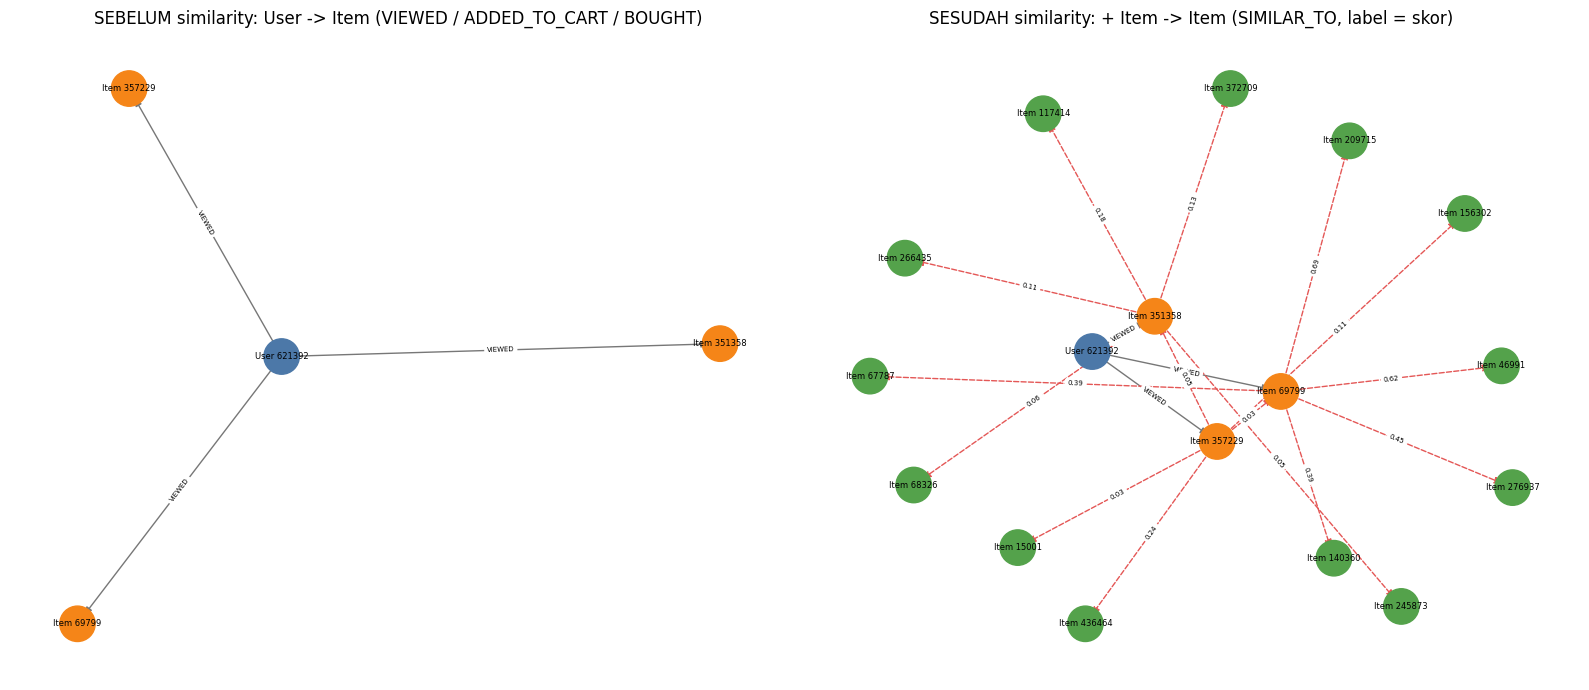

In [25]:
def gambar_ego(ax, ego, ego_sim=None, judul=""):
    G = nx.DiGraph()
    uid_n = f"User {user_terpilih}"
    G.add_node(uid_n, jenis="user")
    for relasi, item in zip(ego["relasi"], ego["item"]):
        G.add_node(f"Item {item}", jenis="item")
        G.add_edge(uid_n, f"Item {item}", relasi=relasi, tipe="interaksi")
    if ego_sim is not None:
        for item, mirip, score in zip(ego_sim["item"], ego_sim["mirip"], ego_sim["score"]):
            if f"Item {mirip}" not in G:
                G.add_node(f"Item {mirip}", jenis="mirip")
            G.add_edge(f"Item {item}", f"Item {mirip}", relasi=f"{score:.2f}", tipe="similar")
    pos = nx.spring_layout(G, seed=7, k=1.2)
    warna = {"user": "#4C78A8", "item": "#F58518", "mirip": "#54A24B"}
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[warna[G.nodes[n]["jenis"]] for n in G], node_size=650)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=6)
    inter = [(a, b) for a, b, d in G.edges(data=True) if d["tipe"] == "interaksi"]
    simil = [(a, b) for a, b, d in G.edges(data=True) if d["tipe"] == "similar"]
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=inter, edge_color="#777777", arrows=True)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=simil, edge_color="#E45756", style="dashed", arrows=True)
    nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=5,
                                 edge_labels={(a, b): d["relasi"] for a, b, d in G.edges(data=True)})
    ax.set_title(judul)
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(16, 7))
gambar_ego(axes[0], ego_sebelum, None, "SEBELUM similarity: User -> Item (VIEWED / ADDED_TO_CART / BOUGHT)")
gambar_ego(axes[1], ego_sebelum, ego_sim, "SESUDAH similarity: + Item -> Item (SIMILAR_TO, label = skor)")
plt.tight_layout()
plt.show()

Untuk screenshot di **Neo4j Browser**, jalankan query berikut (sesudah similarity ditulis):
```
MATCH p = (v:Visitor {visitorId: <visitorId user terpilih>})-[]->(i:Item)-[:SIMILAR_TO]->(o:Item)
RETURN p
```
Query sebelumnya (tanpa SIMILAR_TO): `MATCH p = (v:Visitor {visitorId: <visitorId user terpilih>})-[]->(i:Item) RETURN p`.

In [26]:
driver.close()

## Kesimpulan
1. **Graf:** data interaksi RetailRocket periode P1 (6 Mei - 25 Juli 2015, 1.696.556 kejadian) berhasil dimodelkan menjadi graf berarah di Neo4j dengan 2 jenis simpul (`Visitor` 864.215 dan `Item` 191.337) dan 3 jenis relasi (`VIEWED` 1.641.096, `ADDED_TO_CART` 41.770, `BOUGHT` 13.690). Jumlah relasi sama persis dengan jumlah baris data, jadi impor batch tidak menghilangkan data.
2. **Wrangling:** data dibagi menjadi dua periode yang tidak tumpang tindih lewat filter `timestamp`: P1 (training, 6 Mei - 25 Juli 2015) dan P2 (testing, 26 Juli - 15 Agustus 2015, 411.870 kejadian). Hasilnya disimpan ke dua file CSV.
3. **Proyeksi:** matriks User x Item dan Item x User sama-sama sangat jarang (kepadatan sekitar 0,0008%). Proyeksi **Item lebih baik** karena barisnya jauh lebih sedikit (191.337 dibanding 864.215, sehingga matriks similarity penuh sekitar 20 kali lebih kecil) dan lebih kaya (rata-rata 6,88 non-zero per baris, dibanding 1,52 pada user; 79,9% user hanya menyentuh 1 item).
4. **Similarity dan graf:** cosine similarity antar item dihitung dengan Python lalu ditulis kembali ke Neo4j sebagai relasi `SIMILAR_TO` (0 relasi sebelum, 15 relasi sesudah untuk user terpilih). Query Cypher dengan `ORDER BY ... LIMIT 5` menghasilkan nilai yang sama persis dengan perhitungan Python.
5. **Rekomendasi dan evaluasi:** KNN item-based (k = 5) dipakai untuk merekomendasikan item pada user acak (visitorId 621392). Untuk user ini, Hit@5 = 0 dan NDCG@5 = 0, karena satu-satunya item kunci jawaban (206834) tidak masuk 5 rekomendasi. Pada 300 user acak, rata-rata **Hit@5 = 0,01** dan **NDCG@5 = 0,0042**. Baseline item terpopuler menghasilkan Hit@5 = 0,01 dan NDCG@5 = 0,0056, jadi KNN **belum lebih baik** dari baseline sederhana.
6. **Keterbatasan:** (a) nilai evaluasi sangat rendah karena data sangat jarang: sebagian besar user hanya punya 1 interaksi dan kunci jawaban hanya berisi item baru di periode testing yang pendek (3 minggu); (b) bobot interaksi (1, 3, 5) ditentukan sendiri dan bisa diubah; (c) Hit@5 dan NDCG@5 satu user bersifat kebetulan, sehingga rata-rata 300 user lebih dapat dipercaya; (d) hanya periode P1 yang dimasukkan ke graf, P2 hanya dipakai sebagai kunci jawaban; (e) sebagian user (13 dari 300) hanya mendapat kurang dari 5 rekomendasi karena item mereka tidak punya cukup tetangga.